In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("ea_fc26_goalkeepers.csv")

In [3]:
df.head()

,id,rank,overallRating,firstName,lastName,commonName,birthdate,height,weight,skillMoves,...,team,leagueName,playStyles,playStylesPlus,age,gkDiving,gkHandling,gkKicking,gkPositioning,gkReflexes
0,230621,18,89,Gianluigi,Donnarumma,NaN,1999-02-25,196,90,1,...,Manchester City,Premier League,Footwork,Deflector+,27,90,83,70,87,90
1,212831,22,89,Alisson,Ramses Becker,Alisson,1992-10-02,193,91,1,...,Liverpool,Premier League,"Far Throw,Deflector",Rush Out+,33,86,85,86,90,89
2,192119,28,89,Thibaut,Courtois,NaN,1992-05-11,200,96,1,...,Real Madrid,LALIGA EA SPORTS,"Far Throw,Rush Out",Cross Claimer+,33,85,89,76,88,90
3,200389,43,88,Jan,Oblak,NaN,1993-01-07,188,87,1,...,Atlético de Madrid,LALIGA EA SPORTS,"Far Throw,Far Reach",Cross Claimer+,33,85,90,78,86,87
4,177683,58,87,Yann,Sommer,NaN,1988-12-17,183,77,1,...,Lombardia FC,Serie A Enilive,NaN,Far Reach+,37,83,82,85,87,89


In [9]:
df.isna().sum()

id                       0
rank                     0
overallRating            0
firstName                0
lastName                 0
commonName            1576
birthdate                0
height                   0
weight                   0
skillMoves               0
weakFootAbility          0
preferredFoot            0
position                 0
positionType             0
alternatePositions    1816
nationality              0
team                     0
leagueName               0
playStyles            1142
playStylesPlus        1806
age                      0
gkDiving                 0
gkHandling               0
gkKicking                0
gkPositioning            0
gkReflexes               0
dtype: int64

In [4]:
features = [
    'age', 'height', 'weight', 
    'gkDiving', 'gkHandling', 'gkKicking', 
    'gkPositioning', 'gkReflexes'
]
X = df[features]

In [5]:
y = df['overallRating']

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<Axes: ylabel='age'>

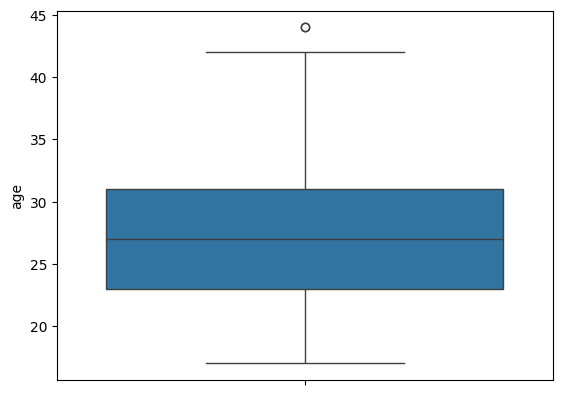

In [10]:
sns.boxplot(X_train['age'])

In [12]:
from sklearn.linear_model import LinearRegression
linear=LinearRegression()
linear.fit(X_train,y_train)
pred=linear.predict(X_test)

In [18]:
from sklearn.metrics import r2_score
n=X_test.shape[0]
k=X_train.shape[1]
r2=r2_score(y_test,pred)
adjusted_r2=1-((1-r2)*(n-1)/(n-k-1))
print(r2)
print(adjusted_r2)

0.9923768485697164
0.99220505924171


In [17]:
from sklearn.tree import DecisionTreeRegressor
tree=DecisionTreeRegressor(random_state=42)
tree.fit(X_train,y_train)
predt=tree.predict(X_test)
r2t=r2_score(y_test,predt)
print(r2t)

0.9705443835127474
